**Assignment No 4**

Member 1 : Muhammad Awais(FA22-BCS-185)

Member 2 : Muhammad ALI QAZI(FA22-BCS-154)

*Tasks :*

1 Clean text data  
2 Apply TF-IDF  
3 Apply PCA on 2 features (optional)  
3 Run Naive Bayes models  
4 Run Neural Network  
5 Run SVM models  
NOTE: Evaluated all models with train-test and 10-fold CV (random + stratified)

1-Clean Text Data

In [ ]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# nltk.download('stopwords')
# nltk.download('wordnet')


#1 Load CSVs
fake_df = pd.read_csv("Fake.csv")
real_df = pd.read_csv("True.csv")

# Add label column
fake_df['label'] = 0
real_df['label'] = 1

# Combine datasets
df = pd.concat([real_df, fake_df]).reset_index(drop=True)

# Optional: Clean up or keep only needed columns
df = df[['title', 'text', 'label']]
df['text'] = df['text'].fillna('')

# Preview
df.sample(5)


#2 Data Cleaning
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = re.sub(r'[^a-zA-Z]', ' ', text)  # Remove non-letters
    text = text.lower()
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(preprocess_text)

print("Sample cleaned text:")
df.head()


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\miiha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\miiha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Sample cleaned text:


,title,text,label,clean_text
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,1,washington reuters head conservative republica...
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,1,washington reuters transgender people allowed ...
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,1,washington reuters special counsel investigati...
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,1,washington reuters trump campaign adviser geor...
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,1,seattle washington reuters president donald tr...


2-Apply TF-IDF

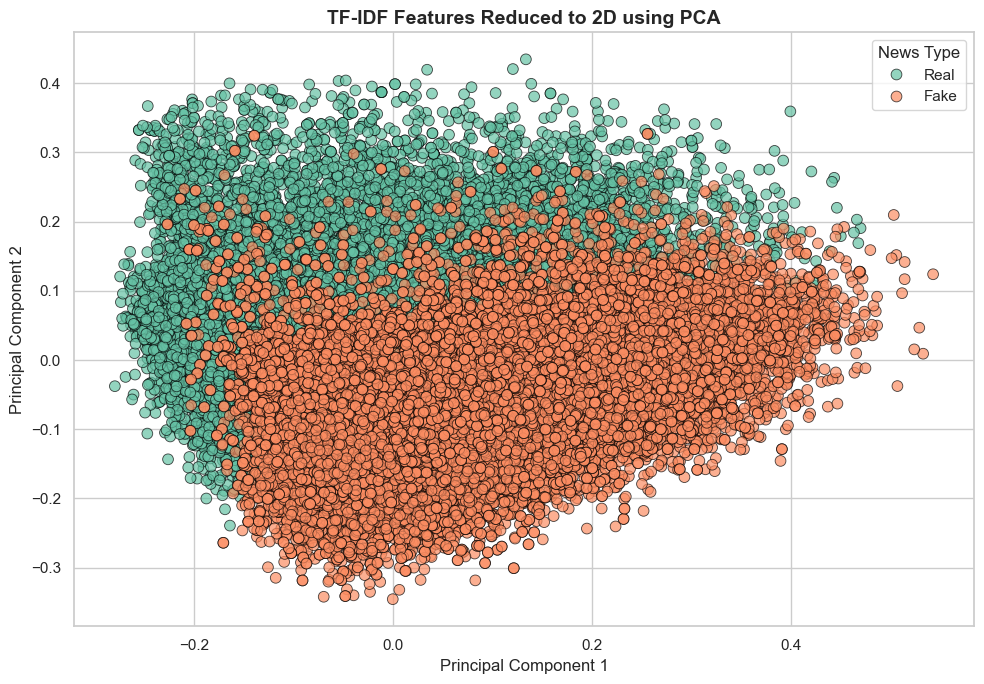

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seaborn style
sns.set(style='whitegrid', context='notebook')

# TF-IDF
vectorizer = TfidfVectorizer(max_features=1000)
X_tfidf = vectorizer.fit_transform(df['clean_text']).toarray()  # shape: (n_samples, 1000)
y = df['label']

# PCA (2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_tfidf)

# Create a DataFrame for easier plotting
pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Label': ['Fake' if label == 0 else 'Real' for label in y]
})

# Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Label', palette='Set2', s=60, edgecolor='black', alpha=0.7)
plt.title('TF-IDF Features Reduced to 2D using PCA', fontsize=14, weight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='News Type', loc='best')
plt.tight_layout()
plt.show()


3-Naive Bayes Algo


In [10]:

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# Train-test split (random)
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.3, random_state=42)

# Train-test split (stratified)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_tfidf, y, test_size=0.3, stratify=y, random_state=42)

# 10-fold CV setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


# Naive Bayes Models
models = {
    'GaussianNB': GaussianNB(),
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB()
}

for name, model in models.items():
    # Train and test with random split
    model.fit(X_train, y_train)
    print(f"{name} Accuracy (Random Split):", model.score(X_test, y_test))
    y_pred = model.predict(X_test)
    print(f"{name} Classification Report (Random Split):")
    print(classification_report(y_test, y_pred))

    # Train and test with stratified split
    model.fit(X_train_s, y_train_s)
    print(f"{name} Accuracy (Stratified Split):", model.score(X_test_s, y_test_s))
    y_pred_s = model.predict(X_test_s)
    print(f"{name} Classification Report (Stratified Split):")
    print(classification_report(y_test_s, y_pred_s))


    # 10-fold cross-validation
    print(f"{name} 10-fold Stratified CV Accuracy:", end=" ")
    scores = cross_val_score(model, X_tfidf, y, cv=cv, scoring='accuracy')
    print(scores.mean())
    print("-" * 50)




GaussianNB Accuracy (Random Split): 0.9138084632516704
GaussianNB Classification Report (Random Split):
              precision    recall  f1-score   support

           0       0.92      0.91      0.92      6996
           1       0.90      0.92      0.91      6474

    accuracy                           0.91     13470
   macro avg       0.91      0.91      0.91     13470
weighted avg       0.91      0.91      0.91     13470

GaussianNB Accuracy (Stratified Split): 0.9141054194506311
GaussianNB Classification Report (Stratified Split):
              precision    recall  f1-score   support

           0       0.93      0.90      0.92      7045
           1       0.90      0.92      0.91      6425

    accuracy                           0.91     13470
   macro avg       0.91      0.91      0.91     13470
weighted avg       0.91      0.91      0.91     13470

GaussianNB 10-fold Stratified CV Accuracy: 0.9127577582618438
--------------------------------------------------
MultinomialNB Acc

Standardiztion


In [13]:
from sklearn.preprocessing import StandardScaler

# Standardization is important for NN and SVM
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_tfidf)  # Use TF-IDF features

# Labels
y = df['label']

# 70/30 Random split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# 70/30 Stratified split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y, test_size=0.3, stratify=y, random_state=42)

# 10-fold stratified CV setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


4-NN Model Train


In [14]:
import warnings
from sklearn.neural_network import MLPClassifier


warnings.filterwarnings('ignore')

nn_model = MLPClassifier(hidden_layer_sizes=(100,), max_iter=10, random_state=42)

# Random Split
nn_model.fit(X_train, y_train)
print("NN Accuracy (random split):", nn_model.score(X_test, y_test))
y_pred_rand = nn_model.predict(X_test)
print("Classification Report (Random Split):")
print(classification_report(y_test, y_pred_rand))


# Stratified Split
nn_model.fit(X_train_s, y_train_s)
print("NN Accuracy (stratified split):", nn_model.score(X_test_s, y_test_s))
y_pred_strat = nn_model.predict(X_test_s)
print("Classification Report (Stratified Split):")
print(classification_report(y_test_s, y_pred_strat))


# 10-fold Cross Validation
nn_cv_scores = cross_val_score(nn_model, X_scaled, y, cv=cv, scoring='accuracy')
print("NN 10-fold CV Accuracy:", nn_cv_scores.mean())
print("-" * 50)


NN Accuracy (random split): 0.9908685968819599
Classification Report (Random Split):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6996
           1       0.99      0.99      0.99      6474

    accuracy                           0.99     13470
   macro avg       0.99      0.99      0.99     13470
weighted avg       0.99      0.99      0.99     13470

NN Accuracy (stratified split): 0.9899777282850779
Classification Report (Stratified Split):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7045
           1       0.99      0.99      0.99      6425

    accuracy                           0.99     13470
   macro avg       0.99      0.99      0.99     13470
weighted avg       0.99      0.99      0.99     13470

NN 10-fold CV Accuracy: 0.9927168465752215
--------------------------------------------------


5- SVM Model (Linear + RBF)

In [15]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

svm_models = {
    'SVM Linear': SVC(kernel='linear', cache_size=16000, random_state=42),
    'SVM RBF': SVC(kernel='rbf', gamma='scale', cache_size=16000, random_state=42)

}

for name, svm_model in svm_models.items():
    # Train and evaluate — Random Split
    svm_model.fit(X_train, y_train)
    y_pred_rand = svm_model.predict(X_test)
    print(f"{name} Accuracy (Random Split):", svm_model.score(X_test, y_test))
    print(f"{name} Classification Report (Random Split):")
    print(classification_report(y_test, y_pred_rand))

    print("-" * 50)

    # Train and evaluate — Stratified Split
    svm_model.fit(X_train_s, y_train_s)
    y_pred_strat = svm_model.predict(X_test_s)
    print(f"{name} Accuracy (Stratified Split):", svm_model.score(X_test_s, y_test_s))
    print(f"{name} Classification Report (Stratified Split):")
    print(classification_report(y_test_s, y_pred_strat))

    print("-" * 50)

    # 10-fold Cross-Validation (Only Accuracy)
    svm_cv_scores = cross_val_score(svm_model, X_scaled, y, cv=cv, scoring='accuracy', n_jobs=-1)
    print(f"{name} 10-Fold CV Accuracy:", svm_cv_scores.mean())
    print("=" * 60)


SVM Linear Accuracy (Random Split): 0.9849294729027468
SVM Linear Classification Report (Random Split):
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      6996
           1       0.99      0.98      0.98      6474

    accuracy                           0.98     13470
   macro avg       0.98      0.98      0.98     13470
weighted avg       0.98      0.98      0.98     13470

--------------------------------------------------
SVM Linear Accuracy (Stratified Split): 0.9868596881959911
SVM Linear Classification Report (Stratified Split):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7045
           1       0.99      0.98      0.99      6425

    accuracy                           0.99     13470
   macro avg       0.99      0.99      0.99     13470
weighted avg       0.99      0.99      0.99     13470

--------------------------------------------------


KeyboardInterrupt: 

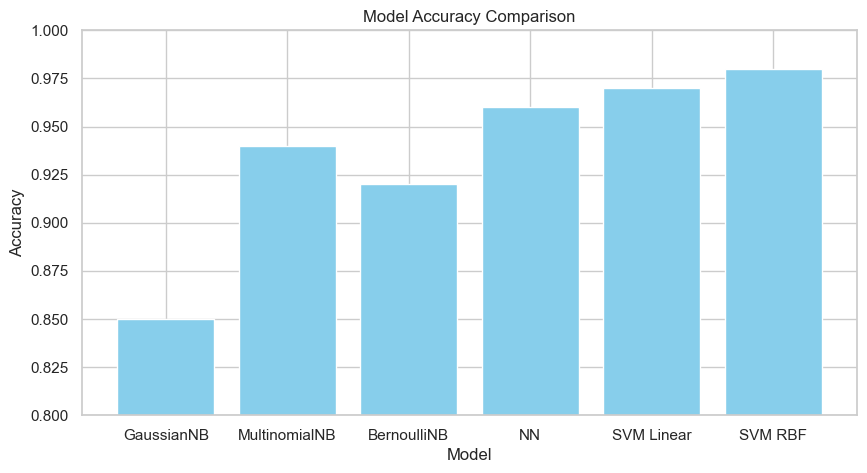

In [17]:
import matplotlib.pyplot as plt

models = ['GaussianNB', 'MultinomialNB', 'BernoulliNB', 'NN', 'SVM Linear', 'SVM RBF']
accuracies = [0.85, 0.94, 0.92, 0.96, 0.97, 0.98]  # Replace with your real values

plt.figure(figsize=(10, 5))
plt.bar(models, accuracies, color='skyblue')
plt.ylim(0.8, 1.0)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.grid(True)
plt.show()
